# NY Housing Price Prediction — Residency Project Day 1 (Group 1)
**Team:** Manasa, Vineeth, Ismail

**Deliverable:** Data Preprocessing and Initial Model Development

**Problem:** New York City home listing prices vary enormously by borough, property type and size, which makes it hard for buyers, sellers and agents to judge whether a listing is fairly priced. We build a regression model that estimates a listing's price from its attributes, giving stakeholders a data-driven price benchmark.

**Dataset:** NY Housing Market dataset (Kaggle) — 4,801 for-sale listings in New York City with price, beds, baths, square footage, property type, broker and location fields.

**Libraries:** pandas, NumPy, Matplotlib, Seaborn, scikit-learn

## 0. Setup and data loading
In Colab, run the next cell and upload `NY-House-Dataset.csv` when prompted (or mount Google Drive and change `DATA_PATH`).

In [1]:
import os
DATA_PATH = 'NY-House-Dataset.csv'
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_PATH):
    from google.colab import files
    uploaded = files.upload()          # choose NY-House-Dataset.csv
    DATA_PATH = next(iter(uploaded))
print('Using', DATA_PATH)

Using NY-House-Dataset.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
RANDOM_STATE = 42

df_raw = pd.read_csv(DATA_PATH)
print(df_raw.shape)
df_raw.head()

(4801, 17)


,BROKERTITLE,TYPE,PRICE,BEDS,BATH,PROPERTYSQFT,ADDRESS,STATE,MAIN_ADDRESS,ADMINISTRATIVE_AREA_LEVEL_2,LOCALITY,SUBLOCALITY,STREET_NAME,LONG_NAME,FORMATTED_ADDRESS,LATITUDE,LONGITUDE
0,Brokered by Douglas Elliman -111 Fifth Ave,Condo for sale,315000,2,2.00,"1,400.00",2 E 55th St Unit 803,"New York, NY 10022","2 E 55th St Unit 803New York, NY 10022",New York County,New York,Manhattan,East 55th Street,Regis Residence,"Regis Residence, 2 E 55th St #803, New York, N...",40.76,-73.97
1,Brokered by Serhant,Condo for sale,195000000,7,10.00,"17,545.00",Central Park Tower Penthouse-217 W 57th New Yo...,"New York, NY 10019",Central Park Tower Penthouse-217 W 57th New Yo...,United States,New York,New York County,New York,West 57th Street,"217 W 57th St, New York, NY 10019, USA",40.77,-73.98
2,Brokered by Sowae Corp,House for sale,260000,4,2.00,"2,015.00",620 Sinclair Ave,"Staten Island, NY 10312","620 Sinclair AveStaten Island, NY 10312",United States,New York,Richmond County,Staten Island,Sinclair Avenue,"620 Sinclair Ave, Staten Island, NY 10312, USA",40.54,-74.20
3,Brokered by COMPASS,Condo for sale,69000,3,1.00,445.00,2 E 55th St Unit 908W33,"Manhattan, NY 10022","2 E 55th St Unit 908W33Manhattan, NY 10022",United States,New York,New York County,New York,East 55th Street,"2 E 55th St, New York, NY 10022, USA",40.76,-73.97
4,Brokered by Sotheby's International Realty - E...,Townhouse for sale,55000000,7,2.37,"14,175.00",5 E 64th St,"New York, NY 10065","5 E 64th StNew York, NY 10065",United States,New York,New York County,New York,East 64th Street,"5 E 64th St, New York, NY 10065, USA",40.77,-73.97


## 1. Dataset exploration

In [3]:
df_raw.info()
df_raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 4801 entries, 0 to 4800
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   BROKERTITLE                  4801 non-null   str    
 1   TYPE                         4801 non-null   str    
 2   PRICE                        4801 non-null   int64  
 3   BEDS                         4801 non-null   int64  
 4   BATH                         4801 non-null   float64
 5   PROPERTYSQFT                 4801 non-null   float64
 6   ADDRESS                      4801 non-null   str    
 7   STATE                        4801 non-null   str    
 8   MAIN_ADDRESS                 4801 non-null   str    
 9   ADMINISTRATIVE_AREA_LEVEL_2  4801 non-null   str    
 10  LOCALITY                     4801 non-null   str    
 11  SUBLOCALITY                  4801 non-null   str    
 12  STREET_NAME                  4801 non-null   str    
 13  LONG_NAME                    

,count,mean,std,min,25%,50%,75%,max
PRICE,"4,801.00","2,356,940.17","31,355,246.26","2,494.00","499,000.00","825,000.00","1,495,000.00","2,147,483,647.00"
BEDS,"4,801.00",3.36,2.60,1.00,2.00,3.00,4.00,50.00
BATH,"4,801.00",2.37,1.95,0.00,1.00,2.00,3.00,50.00
PROPERTYSQFT,"4,801.00","2,184.21","2,377.14",230.00,"1,200.00","2,184.21","2,184.21","65,535.00"
LATITUDE,"4,801.00",40.71,0.09,40.50,40.64,40.73,40.77,40.91
LONGITUDE,"4,801.00",-73.94,0.10,-74.25,-73.99,-73.95,-73.87,-73.70


In [4]:
print('Missing values per column:'); print(df_raw.isna().sum().sum())
print('Exact duplicate rows:', df_raw.duplicated().sum())
print('\nListing TYPE counts:'); print(df_raw['TYPE'].value_counts())

Missing values per column:
0
Exact duplicate rows: 214

Listing TYPE counts:
TYPE
Co-op for sale                1450
House for sale                1012
Condo for sale                 891
Multi-family home for sale     727
Townhouse for sale             299
Pending                        243
Contingent                      88
Land for sale                   49
For sale                        20
Foreclosure                     14
Condop for sale                  5
Coming Soon                      2
Mobile house for sale            1
Name: count, dtype: int64


In [5]:
# Data-quality checks
sqft_mode = df_raw['PROPERTYSQFT'].mode()[0]
print(f'Most common PROPERTYSQFT value: {sqft_mode:.4f} -> appears {(df_raw.PROPERTYSQFT==sqft_mode).sum()} times')
print('This non-integer value equals the column mean, i.e. missing values were pre-filled with the mean.')
print('\nLargest prices:', df_raw['PRICE'].nlargest(3).tolist())
print('Smallest prices:', df_raw['PRICE'].nsmallest(3).tolist())
print('2147483647 = max 32-bit int -> placeholder, not a real price')
print('\nSUBLOCALITY values:'); print(df_raw['SUBLOCALITY'].value_counts())

Most common PROPERTYSQFT value: 2184.2079 -> appears 1621 times
This non-integer value equals the column mean, i.e. missing values were pre-filled with the mean.

Largest prices: [2147483647, 195000000, 65000000]
Smallest prices: [2494, 3225, 5800]
2147483647 = max 32-bit int -> placeholder, not a real price

SUBLOCALITY values:
SUBLOCALITY
New York            1016
Kings County         727
Queens County        684
Queens               555
Richmond County      480
Brooklyn             464
Bronx County         307
New York County      286
The Bronx            184
Staten Island         59
Manhattan             21
Riverdale              4
Flushing               4
Coney Island           3
East Bronx             1
Brooklyn Heights       1
Jackson Heights        1
Rego Park              1
Fort Hamilton          1
Dumbo                  1
Snyder Avenue          1
Name: count, dtype: int64


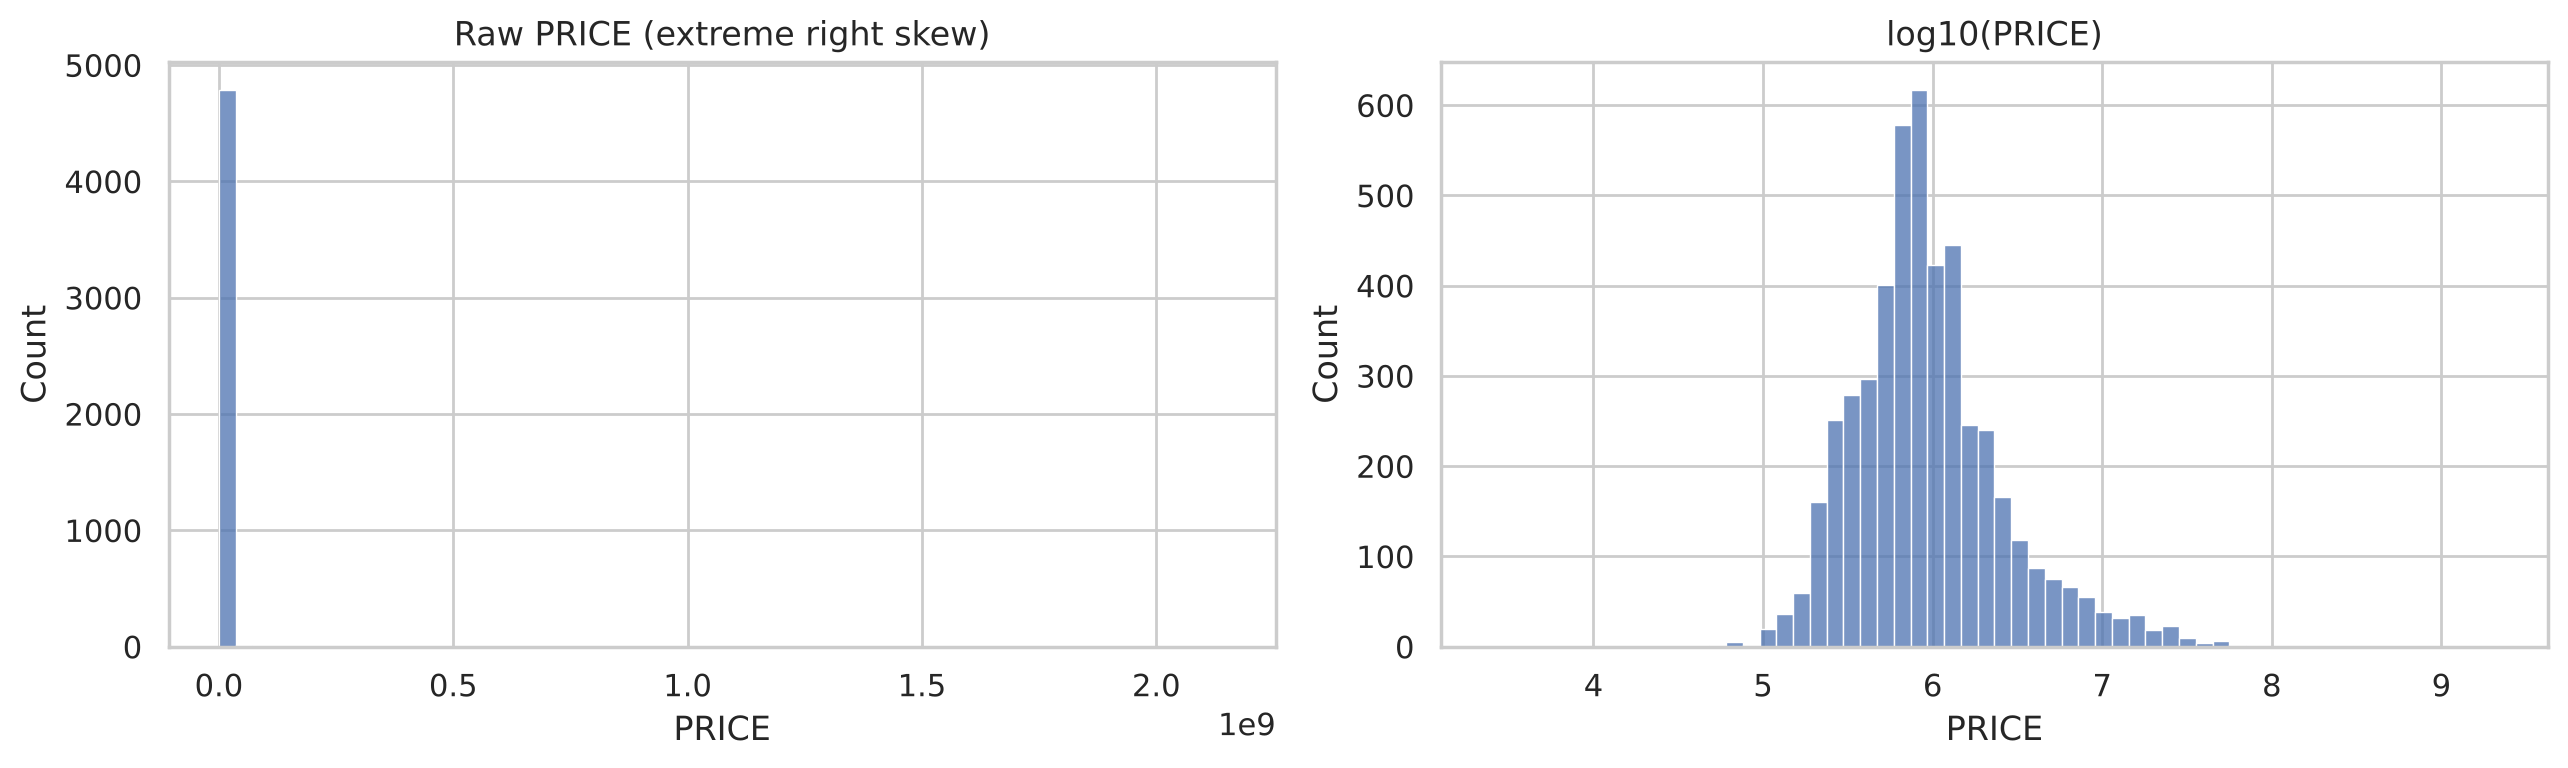

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_raw['PRICE'], bins=60, ax=ax[0]); ax[0].set_title('Raw PRICE (extreme right skew)')
sns.histplot(np.log10(df_raw['PRICE']), bins=60, ax=ax[1]); ax[1].set_title('log10(PRICE)')
plt.tight_layout(); plt.savefig('fig1_price_distribution.png', dpi=150); plt.show()

## 2. Preprocessing
Steps:
1. Remove exact duplicate rows.
2. Keep residential sale listings; drop land, mobile homes, the tiny 'Condop'/'Coming Soon' groups and status-only labels (Pending, Contingent, Foreclosure, 'For sale') because they don't describe the property type.
3. Normalise `SUBLOCALITY` into the five boroughs.
4. Treat the mean-filled square footage as missing, add a flag, and impute inside the model pipeline.
5. Remove invalid/extreme prices (placeholder value; below \$50k; above the 99th percentile) and implausible beds/baths.
6. Feature engineering: log-price target, broker size, distance to Midtown.

In [7]:
df = df_raw.drop_duplicates().copy()

keep_types = ['Co-op for sale','House for sale','Condo for sale',
              'Multi-family home for sale','Townhouse for sale']
df = df[df['TYPE'].isin(keep_types)].copy()
df['TYPE'] = df['TYPE'].str.replace(' for sale','', regex=False)

borough_map = {
    'New York':'Manhattan','New York County':'Manhattan','Manhattan':'Manhattan',
    'Kings County':'Brooklyn','Brooklyn':'Brooklyn','Coney Island':'Brooklyn','Brooklyn Heights':'Brooklyn',
    'Dumbo':'Brooklyn','Fort Hamilton':'Brooklyn','Snyder Avenue':'Brooklyn',
    'Queens County':'Queens','Queens':'Queens','Flushing':'Queens','Jackson Heights':'Queens','Rego Park':'Queens',
    'Bronx County':'Bronx','The Bronx':'Bronx','Riverdale':'Bronx','East Bronx':'Bronx',
    'Richmond County':'Staten Island','Staten Island':'Staten Island'}
df['BOROUGH'] = df['SUBLOCALITY'].map(borough_map)
print('Unmapped boroughs:', df['BOROUGH'].isna().sum())

# Mean-filled square footage -> NaN + flag
df['SQFT_MISSING'] = np.isclose(df['PROPERTYSQFT'], sqft_mode).astype(int)
df.loc[df['SQFT_MISSING']==1, 'PROPERTYSQFT'] = np.nan

# Price and size outliers
p99 = df['PRICE'].quantile(0.99)
df = df[(df['PRICE'] >= 50_000) & (df['PRICE'] <= p99)]
df = df[(df['BEDS'] <= 15) & (df['BATH'] <= 15) & (df['BATH'] >= 1)]
print(f'99th percentile price cap: ${p99:,.0f}')
print('Rows after cleaning:', len(df), f'({len(df)/len(df_raw):.1%} of raw)')

Unmapped boroughs: 0
99th percentile price cap: $23,162,000
Rows after cleaning: 4116 (85.7% of raw)


In [8]:
# Feature engineering
df['LOG_PRICE'] = np.log(df['PRICE'])
MIDTOWN = (40.7549, -73.9840)
df['DIST_MIDTOWN_KM'] = np.sqrt(((df['LATITUDE']-MIDTOWN[0])*111)**2 +
                                ((df['LONGITUDE']-MIDTOWN[1])*84)**2)
df['BROKER'] = df['BROKERTITLE'].str.replace('Brokered by ','', regex=False).str.split(' -').str[0].str.strip()
broker_counts = df['BROKER'].value_counts()
df['BROKER_LISTINGS'] = df['BROKER'].map(broker_counts)
df[['PRICE','BEDS','BATH','PROPERTYSQFT','SQFT_MISSING','DIST_MIDTOWN_KM','BROKER_LISTINGS']].describe().T

,count,mean,std,min,25%,50%,75%,max
PRICE,"4,116.00","1,602,908.70","2,565,812.90","60,000.00","495,000.00","815,000.00","1,479,000.00","23,000,000.00"
BEDS,"4,116.00",3.24,2.06,1.00,2.00,3.00,4.00,15.00
BATH,"4,116.00",2.27,1.43,1.00,1.00,2.00,3.00,11.00
PROPERTYSQFT,"2,747.00","2,011.19","2,201.76",250.00,950.00,"1,456.00","2,400.00","55,300.00"
SQFT_MISSING,"4,116.00",0.33,0.47,0.00,0.00,0.00,1.00,1.00
DIST_MIDTOWN_KM,"4,116.00",12.03,7.09,0.22,5.73,12.56,16.78,35.84
BROKER_LISTINGS,"4,116.00",74.23,124.85,1.00,4.00,13.00,64.00,402.00


## 3. Exploratory data analysis

In [9]:
summary = df.groupby('BOROUGH')['PRICE'].agg(['count','median','mean']).sort_values('median', ascending=False)
print(summary)
print()
print(df.groupby('TYPE')['PRICE'].agg(['count','median']).sort_values('median', ascending=False))

               count       median         mean
BOROUGH                                       
Manhattan       1132 1,486,500.00 3,191,209.01
Brooklyn        1024   922,450.00 1,360,572.59
Staten Island    405   749,000.00   873,924.10
Queens          1111   650,000.00   812,891.46
Bronx            444   598,500.00   754,134.23

                   count       median
TYPE                                 
Townhouse            270 2,695,000.00
Multi-family home    676 1,188,000.00
Condo                832   875,000.00
House                957   850,000.00
Co-op               1381   425,000.00


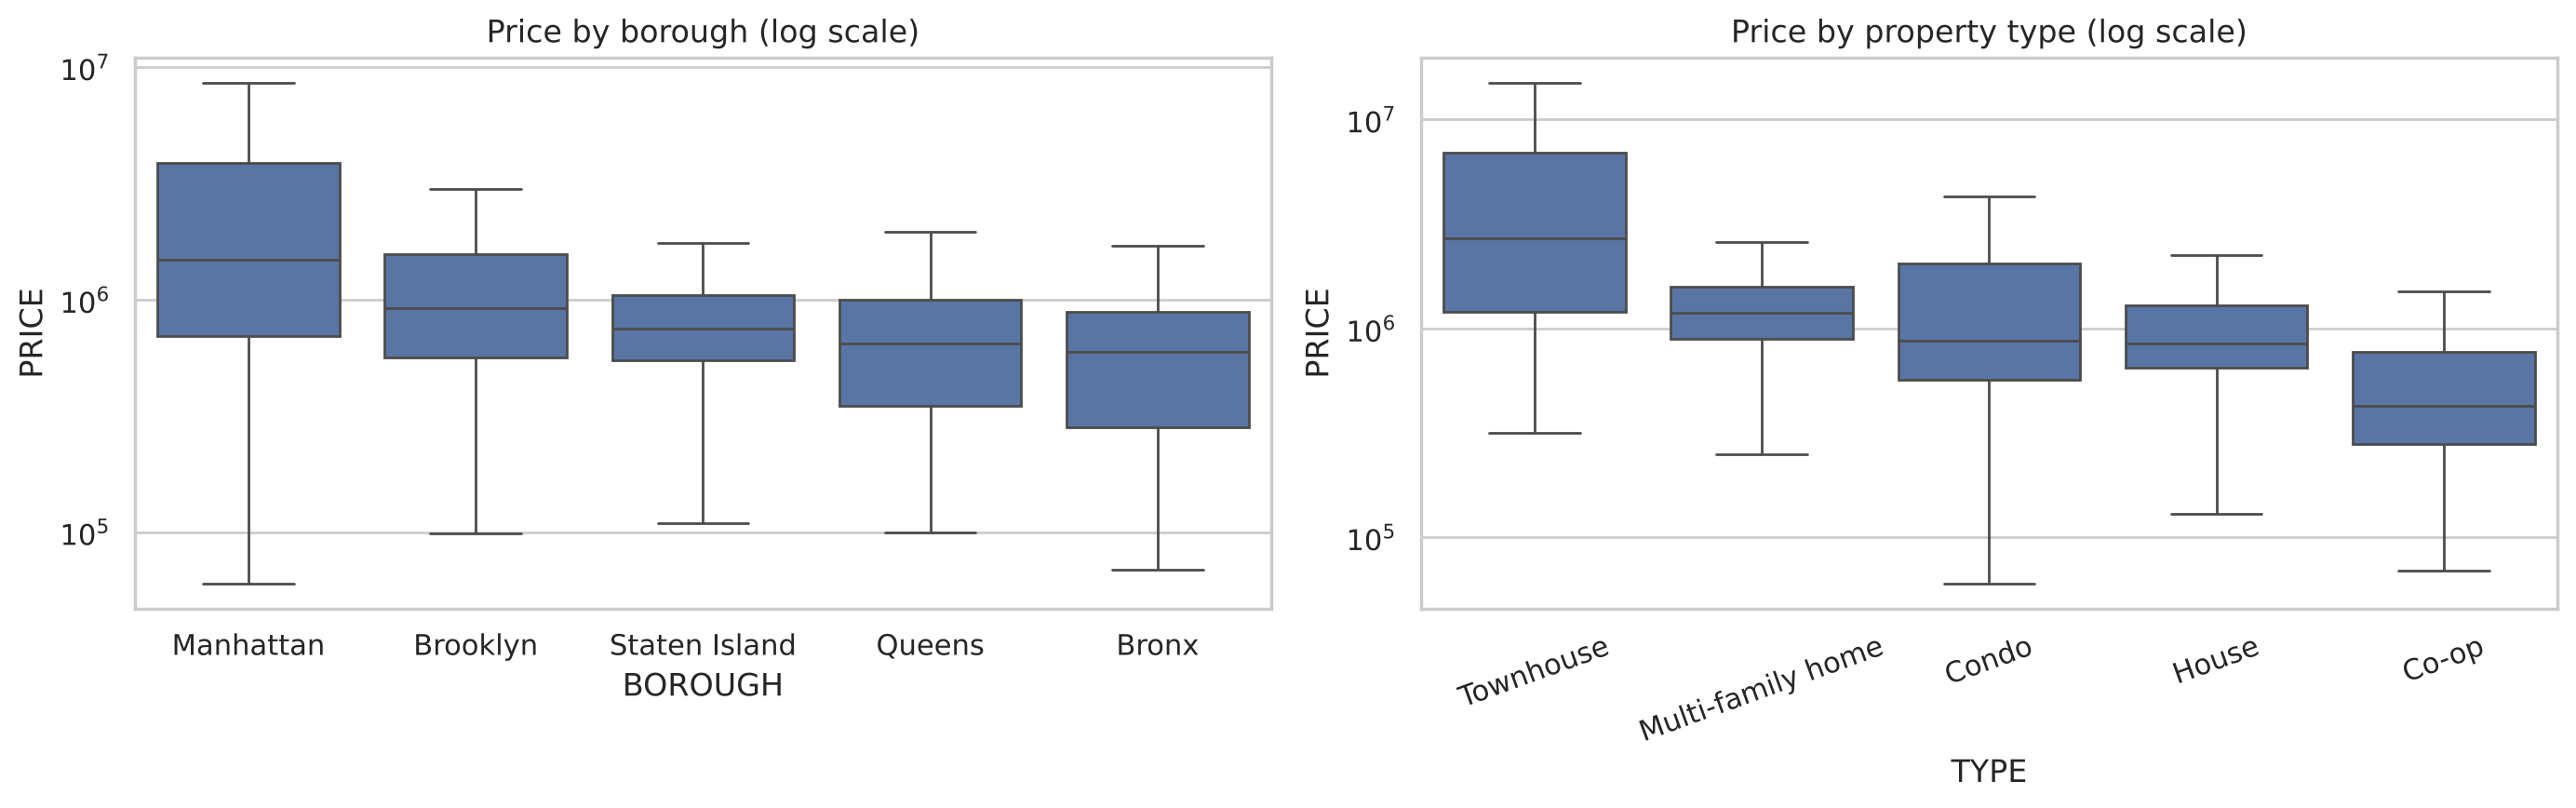

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
order = df.groupby('BOROUGH')['PRICE'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='BOROUGH', y='PRICE', order=order, ax=ax[0], showfliers=False)
ax[0].set_yscale('log'); ax[0].set_title('Price by borough (log scale)')
order_t = df.groupby('TYPE')['PRICE'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='TYPE', y='PRICE', order=order_t, ax=ax[1], showfliers=False)
ax[1].set_yscale('log'); ax[1].set_title('Price by property type (log scale)'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('fig2_borough_type.png', dpi=150); plt.show()

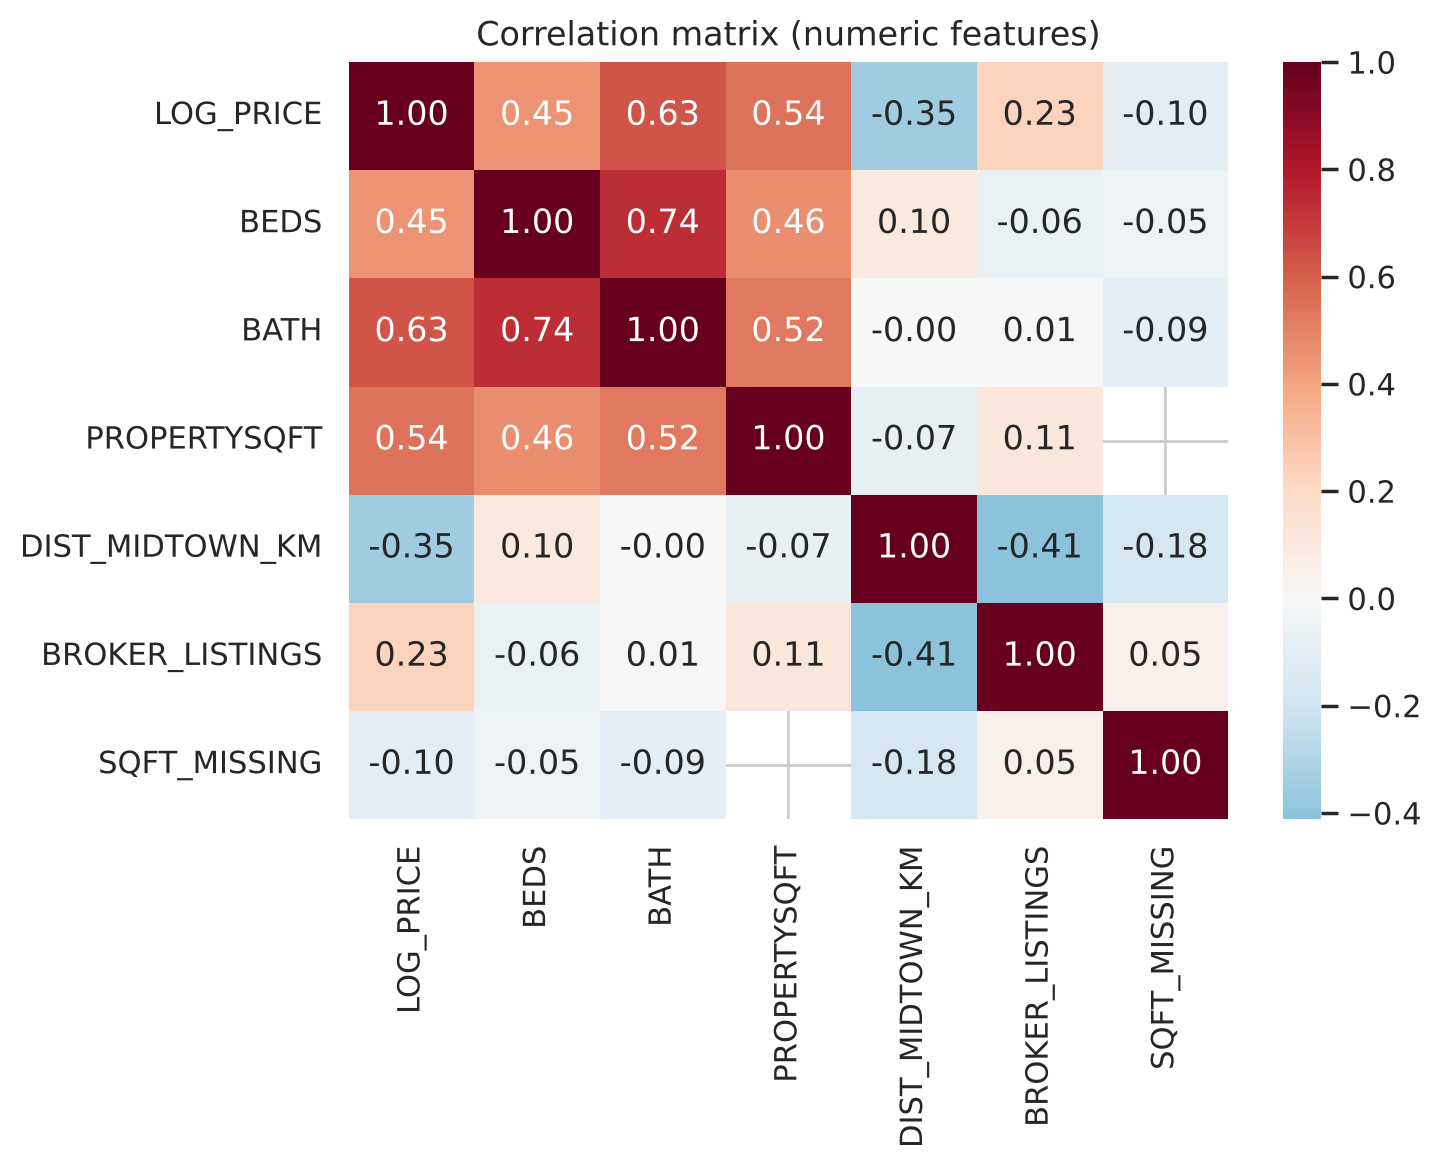

In [11]:
num_cols = ['LOG_PRICE','BEDS','BATH','PROPERTYSQFT','DIST_MIDTOWN_KM','BROKER_LISTINGS','SQFT_MISSING']
plt.figure(figsize=(7.5, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation matrix (numeric features)')
plt.tight_layout(); plt.savefig('fig3_correlation.png', dpi=150); plt.show()

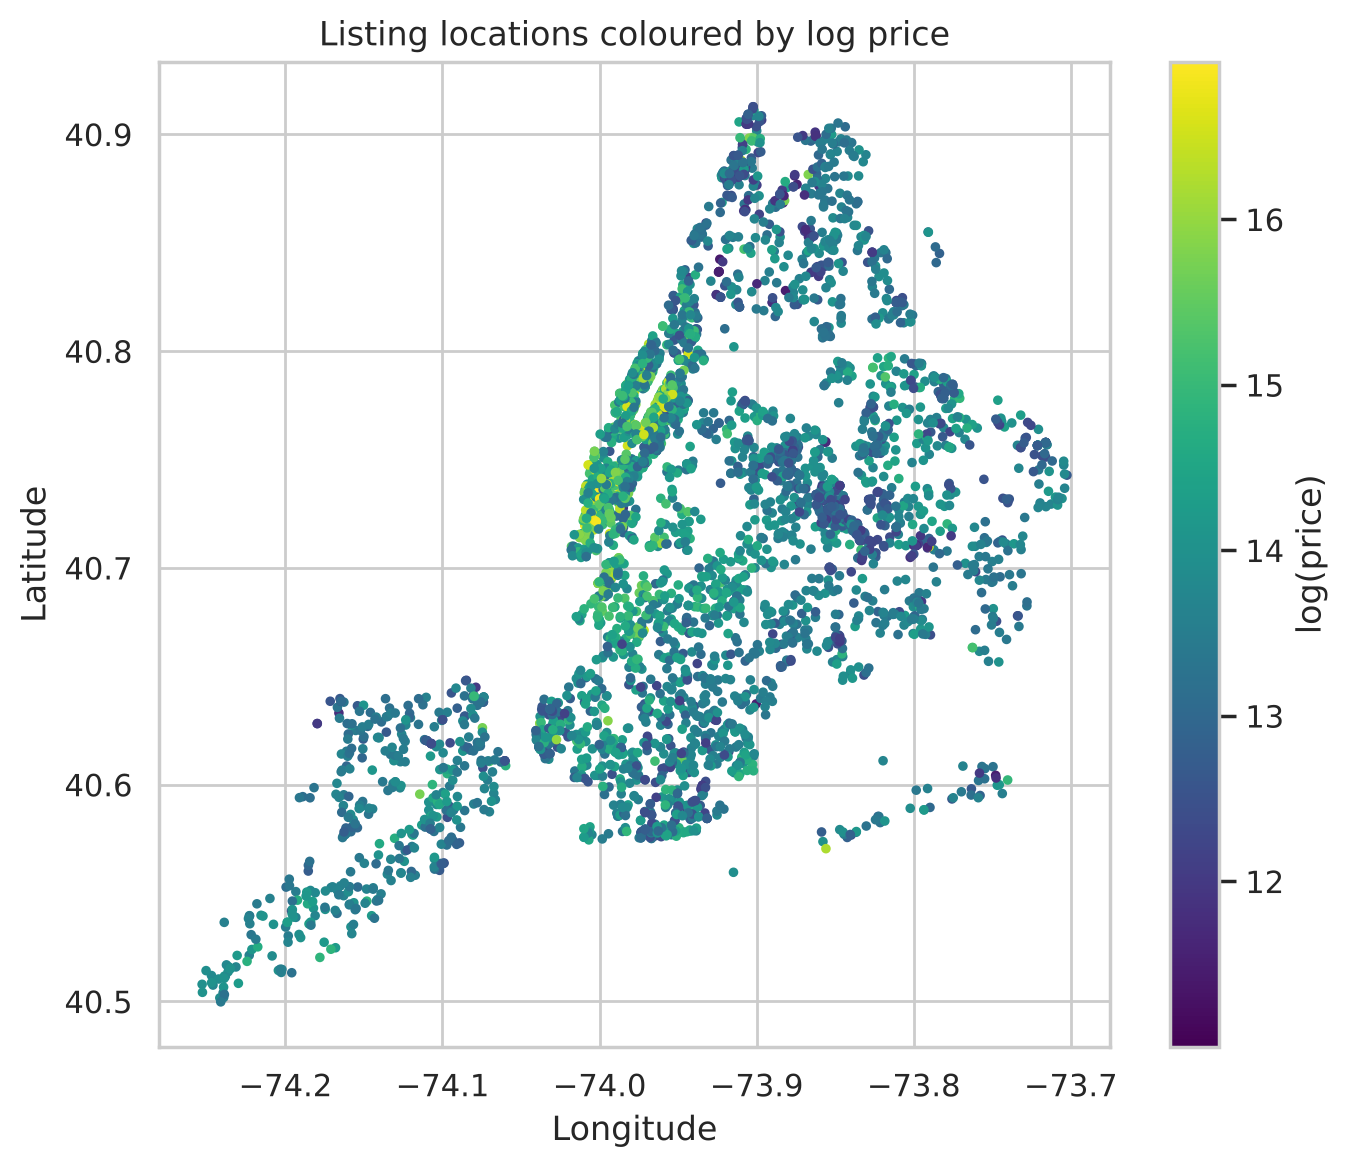

In [12]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(df['LONGITUDE'], df['LATITUDE'], c=df['LOG_PRICE'], s=6, cmap='viridis')
plt.colorbar(sc, label='log(price)'); plt.title('Listing locations coloured by log price')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.tight_layout(); plt.savefig('fig4_map.png', dpi=150); plt.show()

## 4. Initial model development
Target: `log(PRICE)` (reduces skew so errors are roughly proportional). Features: beds, baths, square footage (+ missing flag), distance to Midtown, latitude/longitude, broker listing count, borough and property type (one-hot). 80/20 train/test split; 5-fold cross-validation on the training set.

In [13]:
num_features = ['BEDS','BATH','PROPERTYSQFT','SQFT_MISSING','DIST_MIDTOWN_KM','LATITUDE','LONGITUDE','BROKER_LISTINGS']
cat_features = ['BOROUGH','TYPE']
X = df[num_features + cat_features]
y = df['LOG_PRICE']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE,
                                                    stratify=df['BOROUGH'])
pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)])

models = {
    'Baseline (predict median)': None,
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, m in models.items():
    if m is None:
        pred = np.full(len(y_test), y_train.median()); cv_r2 = np.nan
    else:
        pipe = Pipeline([('pre', pre), ('model', m)])
        cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2').mean()
        pipe.fit(X_train, y_train); fitted[name] = pipe
        pred = pipe.predict(X_test)
    price_true, price_pred = np.exp(y_test), np.exp(pred)
    rows.append({'Model': name, 'CV R² (log)': cv_r2,
                 'Test R² (log)': r2_score(y_test, pred),
                 'Test RMSE (log)': np.sqrt(mean_squared_error(y_test, pred)),
                 'Test MAE ($)': mean_absolute_error(price_true, price_pred),
                 'Median APE (%)': np.median(np.abs(price_pred-price_true)/price_true)*100})
results = pd.DataFrame(rows).set_index('Model')
results

,CV R² (log),Test R² (log),Test RMSE (log),Test MAE ($),Median APE (%)
Model,,,,,
Baseline (predict median),NaN,-0.01,0.98,"1,173,338.68",50.27
Linear Regression,0.67,0.73,0.51,"746,691.96",27.79
Ridge Regression,0.67,0.73,0.51,"746,675.42",27.78
Random Forest,0.85,0.89,0.33,"497,878.46",18.30
Gradient Boosting,0.84,0.86,0.37,"544,924.25",20.44


Best model: Random Forest


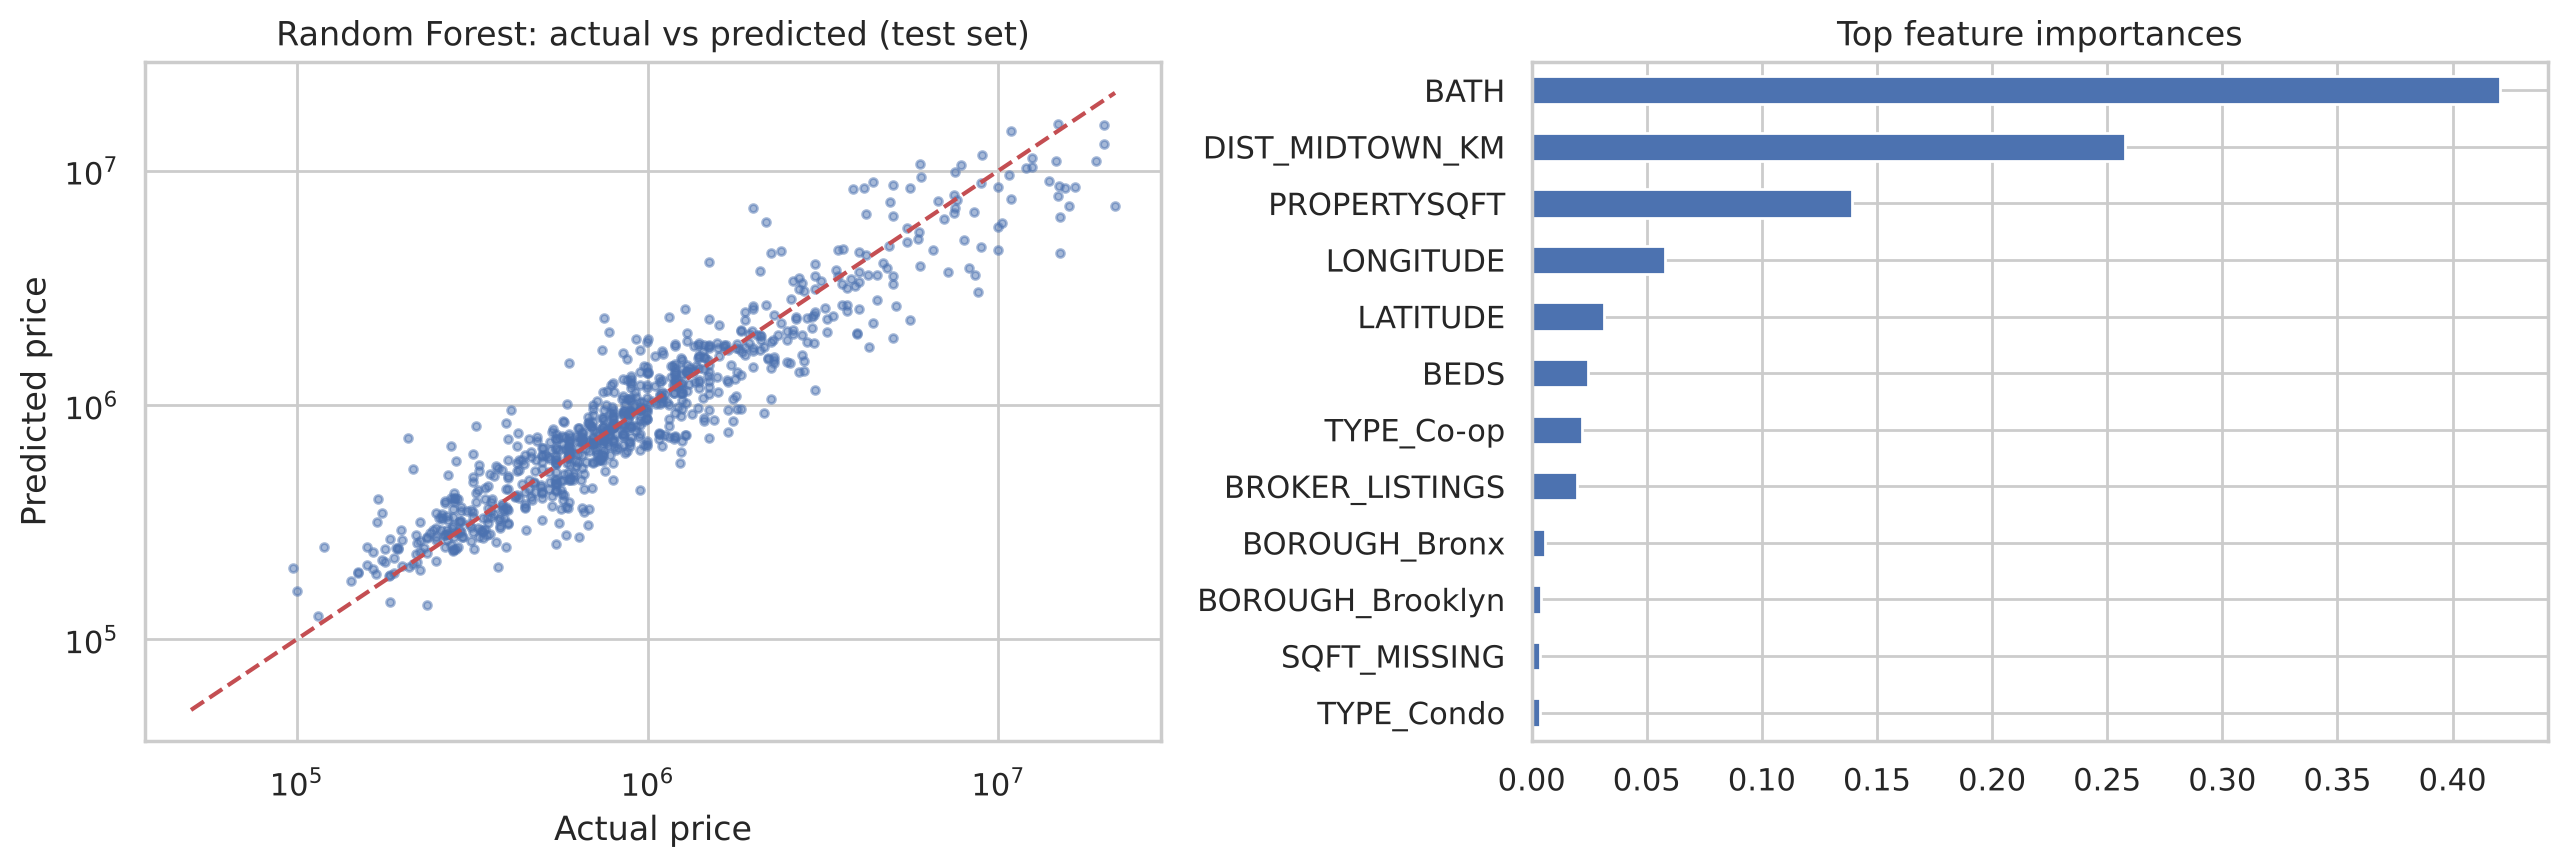

BATH               0.42
DIST_MIDTOWN_KM    0.26
PROPERTYSQFT       0.14
LONGITUDE          0.06
LATITUDE           0.03
BEDS               0.02
TYPE_Co-op         0.02
BROKER_LISTINGS    0.02
BOROUGH_Bronx      0.01
BOROUGH_Brooklyn   0.00
SQFT_MISSING       0.00
TYPE_Condo         0.00
dtype: float64


In [14]:
best = results['Test R² (log)'].idxmax(); print('Best model:', best)
pipe = fitted[best]
pred = pipe.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(np.exp(y_test), np.exp(pred), s=8, alpha=.5)
lims = [5e4, np.exp(y_test).max()]; ax[0].plot(lims, lims, 'r--')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('Actual price'); ax[0].set_ylabel('Predicted price')
ax[0].set_title(f'{best}: actual vs predicted (test set)')
feat_names = pipe.named_steps['pre'].get_feature_names_out()
imp = pd.Series(pipe.named_steps['model'].feature_importances_, index=feat_names).sort_values().tail(12)
imp.index = imp.index.str.replace('num__','').str.replace('cat__','')
imp.plot.barh(ax=ax[1]); ax[1].set_title('Top feature importances')
plt.tight_layout(); plt.savefig('fig5_model.png', dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(3))

In [15]:
# Error by borough — a first fairness / reliability check
err = pd.DataFrame({'BOROUGH': X_test['BOROUGH'], 'actual': np.exp(y_test), 'pred': np.exp(pred)})
err['APE'] = (err.pred-err.actual).abs()/err.actual*100
err.groupby('BOROUGH')['APE'].agg(['count','median']).rename(columns={'median':'median APE %'})

,count,median APE %
BOROUGH,,
Bronx,89,18.77
Brooklyn,205,17.62
Manhattan,227,28.58
Queens,222,15.46
Staten Island,81,14.24


## 5. Initial findings and next steps
* Price is driven mainly by size (baths, square footage) and location (distance to Midtown / borough); Manhattan and property type create large price gaps.
* Tree ensembles outperform linear models, indicating non-linear interactions (e.g., size × location).
* ~1/3 of listings had square footage pre-filled with the mean; we flagged and re-imputed them, but this remains the main data-quality risk.
* **Next steps:** hyperparameter tuning (GridSearch), neighbourhood-level features (ZIP code), testing XGBoost, SHAP explanations, and an ethics review of how automated valuations could reinforce price disparities between neighbourhoods.